# Advanced Natural Language Processing (968G5): Practical Assignment (Max 5000 words) - Propaganda Detection

## 1. Setup

### 1.1. Load Libraries

In [263]:
from datasets import Dataset
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.naive_bayes import MultinomialNB
from torch.optim import AdamW
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import AutoModelForSequenceClassification, BertTokenizer, DataCollatorWithPadding
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pickle
import re
import seaborn as sns
import torch

### 1.2. Initialise Settings

In [264]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
seed = 123

### 1.3. Create Folders

In [265]:
folders = ["data", "figures", "metrics"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

### 1.4. Read in Data

In [266]:
train_df = pd.read_csv("data/propaganda_train.tsv", sep="\t")
test_df = pd.read_csv("data/propaganda_val.tsv", sep="\t")

### 1.5. Data Preprocessing

#### 1.5.1. Cleaned Text

This is just used for EDA

In [267]:
train_df["cleaned_text"] = (
    train_df["tagged_in_context"].apply(
        lambda x: re.sub(
            r"\s+", 
            " ", 
            x.replace("<BOS>", "").replace("<EOS>", "")
        )
        .strip()
    )
)

test_df["cleaned_text"] = (
    test_df["tagged_in_context"].apply(
        lambda x: re.sub(
            r"\s+", 
            " ", 
            x.replace("<BOS>", "").replace("<EOS>", "")
        )
        .strip()
    )
)

In [268]:
train_df["cleaned_text_len"] = train_df["cleaned_text"].apply(lambda x: len(x.split()))
test_df["cleaned_text_len"] = test_df["cleaned_text"].apply(lambda x: len(x.split()))

## 2. EDA

In [269]:
train_proportion_df = train_df["label"].value_counts(normalize=True).reset_index()
train_proportion_df["split"] = "train"

test_proportion_df = test_df["label"].value_counts(normalize=True).reset_index()
test_proportion_df["split"] = "test"

combined_proportion_df = pd.concat([train_proportion_df, test_proportion_df])

### 2.1. Class Distribution

In [270]:
labels = sorted(combined_proportion_df["label"].unique())
labels.remove("not_propaganda")
order = ["not_propaganda"] + labels  
palette = {k: v for k, v in zip(order, sns.color_palette()[:len(order)])}

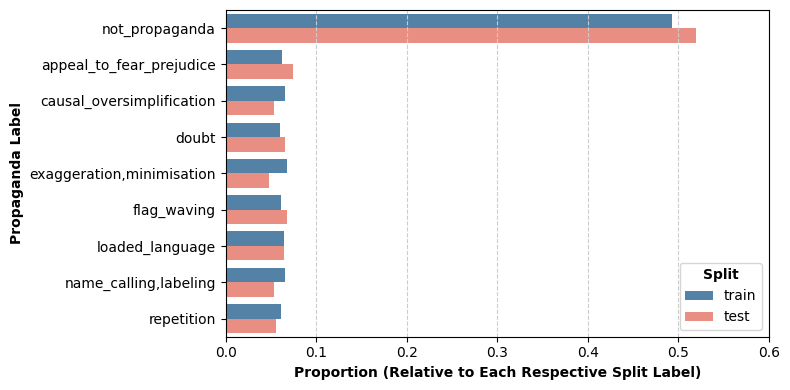

In [271]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=combined_proportion_df,
    x="proportion",
    y="label",
    hue="split",
    order=order,
    palette={"train": "steelblue", "test": "salmon"}
)

plt.xlabel("Proportion (Relative to Each Respective Split Label)", fontsize=10, fontweight="bold")
plt.ylabel("Propaganda Label", fontsize=10, fontweight="bold")

plt.xlim(0, 0.6)

plt.grid(axis="x", color="0.8", linestyle="--")

plt.legend(
    title="Split",
    title_fontproperties={
        "size": 10, 
        "weight": "bold"
    }
)

plt.tight_layout()
plt.savefig(
    "figures/class_distribution_comparison_plot.png",
    dpi=600
)
plt.show()

### 2.2 Character Counts per Label

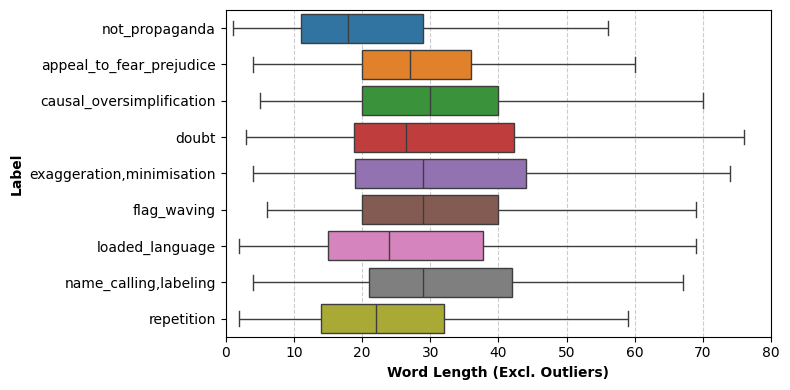

In [272]:
plt.figure(figsize=(8,4))

sns.boxplot(
    data=train_df,
    x="cleaned_text_len",
    y="label",
    hue="label",
    order=order,
    palette=palette,
    showfliers=False
)

plt.xlabel("Word Length (Excl. Outliers)", fontsize=10, fontweight="bold")
plt.xlim(0, 80)

plt.ylabel("Label", fontsize=10, fontweight="bold")

plt.grid(axis="x", color="0.8", linestyle="--")

plt.tight_layout()
plt.savefig("figures/word_length_by_label_plot.png", dpi=600)
plt.show()

## 3. Modelling

### 3.1. Propaganda Snippet Multimodal Classification

In [273]:
propaganda_only_train_df = train_df[train_df["label"] != "not_propaganda"][["label", "tagged_in_context"]].reset_index(drop=True)
propaganda_only_test_df = test_df[test_df["label"] != "not_propaganda"][["label", "tagged_in_context"]].reset_index(drop=True)

#### 3.1.1. Method 1: Multimodal Naive Bayes

In [274]:
def add_prefix_to_words(list_of_words):

    inside_snippet = False
    new_list_of_words = []

    for word in list_of_words:

        if word in ENGLISH_STOP_WORDS:
            continue

        if "<BOS>" in word.upper():
            inside_snippet = True
            continue

        if "<EOS>" in word.upper():
            inside_snippet = False
            continue

        cleaned_word = re.sub(r"[^a-zA-Z0-9]", "", word).lower()
        if not cleaned_word:
            continue

        if inside_snippet:
            new_list_of_words.append("SNIPPET_" + cleaned_word)
        if not inside_snippet:
            new_list_of_words.append("CONTEXT_" + cleaned_word)        

    return new_list_of_words

In [275]:
propaganda_only_train_df["prefixed_text"] = propaganda_only_train_df["tagged_in_context"].apply(
    lambda x: " ".join(add_prefix_to_words(x.strip().split(" ")))
    # lambda x: " ".join(x.strip().replace("<BOS>", "").replace("<EOS>", "").split(" "))
)

propaganda_only_test_df["prefixed_text"] = propaganda_only_test_df["tagged_in_context"].apply(
    lambda x: " ".join(add_prefix_to_words(x.strip().split(" ")))
    # lambda x: " ".join(x.strip().replace("<BOS>", "").replace("<EOS>", "").split(" "))
)

In [276]:
vectoriser = TfidfVectorizer(ngram_range=(1, 3), min_df=2) # unigram BoW representation
X_train_vectors = vectoriser.fit_transform(propaganda_only_train_df["prefixed_text"])
X_test_vectors = vectoriser.transform(propaganda_only_test_df["prefixed_text"])

In [277]:
classifier=MultinomialNB()
classifier.fit(X_train_vectors, propaganda_only_train_df["label"])
y_pred = classifier.predict(X_test_vectors)
y_true = propaganda_only_test_df["label"]

In [278]:
with open("metrics/multimodalNB_accuracy.pkl", "wb") as f:
    pickle.dump(accuracy_score(y_true, y_pred), f)

print(f"{accuracy_score(y_true, y_pred):.3f}")

0.430


In [279]:
multinomialNB_classification_report = classification_report(
    y_true, 
    y_pred, 
    output_dict=True
)

In [280]:
multinomialNB_classification_report_df = (
    pd.DataFrame(multinomialNB_classification_report)
    .drop(columns="accuracy")
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)

multinomialNB_classification_report_df["label"] = multinomialNB_classification_report_df["label"].apply(
    lambda x: x.replace("_", " ").title()
)

multinomialNB_classification_report_df.columns = [c.title() for c in multinomialNB_classification_report_df.columns]
multinomialNB_classification_report_df

,Label,Precision,Recall,F1-Score
0,Appeal To Fear Prejudice,0.470588,0.558140,0.510638
1,Causal Oversimplification,0.411765,0.451613,0.430769
2,Doubt,0.485714,0.447368,0.465753
3,"Exaggeration,Minimisation",0.375000,0.642857,0.473684
4,Flag Waving,0.558140,0.615385,0.585366
5,Loaded Language,0.266667,0.108108,0.153846
6,"Name Calling,Labeling",0.333333,0.322581,0.327869
7,Repetition,0.391304,0.281250,0.327273
8,Macro Avg,0.411564,0.428413,0.409400
9,Weighted Avg,0.417370,0.430108,0.413732


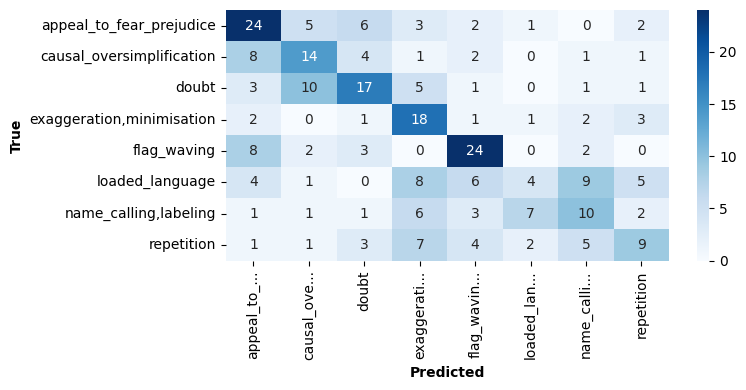

In [281]:
conf_matrix = confusion_matrix(
    y_true, 
    y_pred, 
    labels=classifier.classes_
)

truncated_class_labels = [str(c)[:10] + "..." if len(c) > 10 else str(c) for c in classifier.classes_]

plt.figure(figsize=(8,4))

sns.heatmap(
    conf_matrix, 
    annot=True, 
    xticklabels=truncated_class_labels, 
    yticklabels=classifier.classes_, 
    cmap="Blues"
)

plt.xlabel("Predicted", fontsize=10, fontweight="bold")
plt.ylabel("True", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/mutlinomialNB_confusion_matrix_plot.png", dpi=600)
plt.show()

In [283]:
feature_log_probs = classifier.feature_log_prob_
feature_names = vectoriser.get_feature_names_out()
classes = classifier.classes_

for i, c in enumerate(classes):
    log_odds = feature_log_probs[i] - np.log(
        np.mean(np.exp(feature_log_probs[np.arange(len(classes)) != i]), axis=0)
    )
    sorted_idx = np.argsort(log_odds)[::-1]

    context_features = [
        feature_names[j].replace("context_", "") for j in sorted_idx if feature_names[j].startswith("context_")
    ][:5]

    snippet_features = [
        feature_names[j].replace("snippet_", "") for j in sorted_idx if feature_names[j].startswith("snippet_")
    ][:5]

    print(f"\nTop features for {c}:")
    print(f"Context features: {context_features}")
    print(f"Snippet features: {snippet_features}")


Top features for appeal_to_fear_prejudice:
Context features: ['letter', 'tells', 'plague', 'iranian', 'warned']
Snippet features: ['face', 'west', 'europe', 'iran', 'if']

Top features for causal_oversimplification:
Context features: ['words', 'in words', 'on hand', 'except', 'strong']
Snippet features: ['clearly', 'they', 'it', 'job', 'cia']

Top features for doubt:
Context features: ['shooting', 'las', 'las vegas', 'vegas', 'question']
Snippet features: ['guardian', 'evidence', 'what', 'wouldnt', 'does']

Top features for exaggeration,minimisation:
Context features: ['is', 'thought', 'nasa', 'mistake', 'earth']
Snippet features: ['history', 'worst', 'thing', 'world', 'no']

Top features for flag_waving:
Context features: ['military', 'trade', 'continue', 'trump', 'iran']
Snippet features: ['american', 'american people', 'america', 'americans', 'people']

Top features for loaded_language:
Context features: ['evidence', 'ratzinger', 'knew', 'wrong', 'synodal']
Snippet features: ['inde

#### 3.1.2. Method 2: BERT

##### 3.1.2.1. BERT Hyperparameters

In [22]:
batch_size = 8
learning_rate = 1e-5
num_epochs = 5
pretrained_bert_model = "distilbert-base-uncased"
validation_set_size = 0.1

In [23]:
train_dataset = Dataset.from_pandas(propaganda_only_train_df[["label", "tagged_in_context"]])
test_dataset = Dataset.from_pandas(propaganda_only_test_df[["label", "tagged_in_context"]])

In [24]:
unique_labels = sorted(propaganda_only_train_df["label"].unique())
label2id = {label: i for i, label in enumerate(unique_labels)}
id2label = {i: label for i, label in enumerate(unique_labels)}

tokeniser = BertTokenizer.from_pretrained(pretrained_bert_model)

special_tokens = {"additional_special_tokens": ["<BOS>", "<EOS>"]}
tokeniser.add_special_tokens(special_tokens)

model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_bert_model, 
    num_labels=len(unique_labels), 
    id2label=id2label, 
    label2id=label2id
)

model.resize_token_embeddings(len(tokeniser))

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3283.75it/s]
DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nl

Embedding(30524, 768, padding_idx=0)

In [25]:
def tokenize(example):
    return tokeniser(
        example["tagged_in_context"],
        truncation=True,
        max_length=512
    )

def add_labels(example):
    example["labels"] = label2id[example["label"]]
    return example

train_dataset = train_dataset.map(tokenize, batched=True)
train_dataset = train_dataset.map(add_labels)

test_dataset = test_dataset.map(tokenize, batched=True)
test_dataset = test_dataset.map(add_labels)

train_dataset = train_dataset.remove_columns(["label"])
test_dataset = test_dataset.remove_columns(["label"])

train_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

test_dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

data_collator = DataCollatorWithPadding(tokenizer=tokeniser)

Map: 100%|██████████| 279/279 [00:00<00:00, 16376.89 examples/s]


In [26]:
train_validation_dataset = train_dataset.train_test_split(
    test_size=validation_set_size, 
    seed=seed
)

In [27]:
train_loader = DataLoader(
    train_validation_dataset["train"],
    batch_size=batch_size,
    shuffle=True,
    collate_fn=data_collator
)

val_loader = DataLoader(
    train_validation_dataset["test"],
    batch_size=batch_size,
    collate_fn=data_collator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    collate_fn=data_collator
)

In [28]:
optimiser = AdamW(model.parameters(), lr=learning_rate)

model = model.to(device)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Processing Batches from Epoch {epoch+1}"):
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        loss = outputs.loss

        optimiser.zero_grad()
        loss.backward()
        optimiser.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)

    model.eval()
    val_preds = []
    val_true = []
    val_loss = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}

            outputs = model(**batch)
            val_loss += outputs.loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_true.extend(batch["labels"].cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_f1 = f1_score(val_true, val_preds, average="weighted")

    print(f"--- Epoch {epoch+1} Results ---")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Val Loss: {avg_val_loss:.4f}")
    print(f"Val F1: {val_f1:.4f}\n")

Processing Batches from Epoch 1: 100%|██████████| 138/138 [00:07<00:00, 18.74it/s]


--- Epoch 1 Results ---
Train Loss: 2.0720
Val Loss: 2.0537
Val F1: 0.1434



Processing Batches from Epoch 2: 100%|██████████| 138/138 [00:06<00:00, 21.21it/s]


--- Epoch 2 Results ---
Train Loss: 1.9226
Val Loss: 1.8363
Val F1: 0.3294



Processing Batches from Epoch 3: 100%|██████████| 138/138 [00:06<00:00, 21.00it/s]


--- Epoch 3 Results ---
Train Loss: 1.5924
Val Loss: 1.5766
Val F1: 0.3732



Processing Batches from Epoch 4: 100%|██████████| 138/138 [00:06<00:00, 21.25it/s]


--- Epoch 4 Results ---
Train Loss: 1.2391
Val Loss: 1.3786
Val F1: 0.5268



Processing Batches from Epoch 5: 100%|██████████| 138/138 [00:06<00:00, 21.04it/s]


--- Epoch 5 Results ---
Train Loss: 0.8822
Val Loss: 1.3225
Val F1: 0.5191



In [29]:
model.eval()

test_preds = []
test_true = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        logits = outputs.logits

        preds = torch.argmax(logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_true.extend(batch["labels"].cpu().numpy())

bert_accuracy = accuracy_score(test_true, test_preds)
bert_f1_score = f1_score(test_true, test_preds, average="weighted")

print(f"Test Accuracy: {bert_accuracy:.4f}")
print(f"Test F1: {bert_f1_score:.4f}")

Test Accuracy: 0.5305
Test F1: 0.5275


In [30]:
BERT_classification_report = classification_report(
    test_true, 
    test_preds, 
    output_dict=True
)

In [31]:
BERT_classification_report_label_mapping = {str(k): v for k, v in id2label.items()}

In [32]:
BERT_classification_report_df = (
    pd.DataFrame(BERT_classification_report)
    .drop(columns="accuracy")
    .transpose()
    .drop(columns="support")
    .reset_index(names="label")
)

BERT_classification_report_df["label"] = (
    BERT_classification_report_df["label"]
    .map(BERT_classification_report_label_mapping)
    .fillna(BERT_classification_report_df["label"])
)

BERT_classification_report_df["label"] = BERT_classification_report_df["label"].apply(
    lambda x: x.replace("_", " ").title()
)

BERT_classification_report_df.columns = [c.title() for c in BERT_classification_report_df.columns]

BERT_classification_report_df

,Label,Precision,Recall,F1-Score
0,Appeal To Fear Prejudice,0.507692,0.767442,0.611111
1,Causal Oversimplification,0.739130,0.548387,0.629630
2,Doubt,0.741935,0.605263,0.666667
3,"Exaggeration,Minimisation",0.411765,0.250000,0.311111
4,Flag Waving,0.613636,0.692308,0.650602
5,Loaded Language,0.400000,0.324324,0.358209
6,"Name Calling,Labeling",0.666667,0.451613,0.538462
7,Repetition,0.312500,0.468750,0.375000
8,Macro Avg,0.549166,0.513511,0.517599
9,Weighted Avg,0.551488,0.530466,0.527456


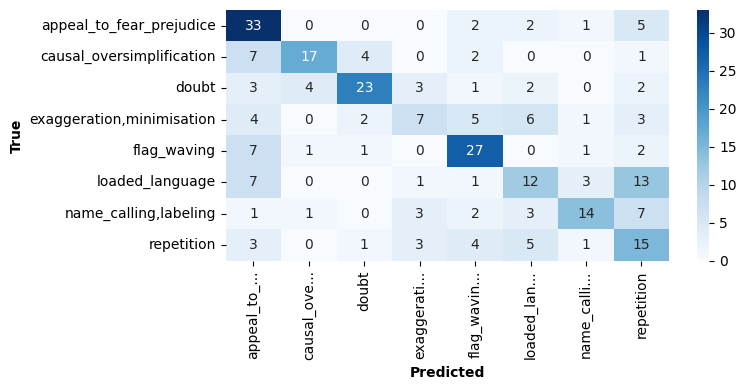

In [33]:
conf_matrix = confusion_matrix(
    test_true, 
    test_preds
)

truncated_class_labels = [str(c)[:10] + "..." if len(c) > 10 else str(c) for c in unique_labels]

plt.figure(figsize=(8,4))

sns.heatmap(
    conf_matrix, 
    annot=True, 
    xticklabels=truncated_class_labels, 
    yticklabels=unique_labels, 
    cmap="Blues"
)

plt.xlabel("Predicted", fontsize=10, fontweight="bold")
plt.ylabel("True", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("figures/BERT_confusion_matrix_plot.png", dpi=600)
plt.show()

### 3.2 Propaganda Span Identification + Multimodal Classification

In [38]:
def bio_tagging(row):
    label = row["label"]
    text = row["tagged_in_context"]

    list_of_words = text.split(" ")
    list_of_bio_tagged_words = []

    inside_span = False
    first_word_in_span = False

    for word in list_of_words:

        if word == "<BOS>":
            inside_span = True
            first_word_in_span = True
            continue
        
        if word == "<EOS>":
            inside_span = False
            continue

        if inside_span:

            if first_word_in_span:
                tag = f"B_{label}"
                first_word_in_span = False

            else:
                tag = f"I_{label}"

        else:
            tag = "O"

        list_of_bio_tagged_words.append((word, tag))

    return list_of_bio_tagged_words

In [ ]:
train_df["bio_tagged_text"] = train_df.apply(
    bio_tagging, axis=1
)

test_df["bio_tagged_text"] = test_df.apply(
    bio_tagging, axis=1
)

In [45]:
train_df[["label", "tagged_in_context"]]

,label,tagged_in_context
0,not_propaganda,"No, <BOS> he <EOS> will not be confirmed."
1,not_propaganda,This declassification effort <BOS> won’t make ...
2,flag_waving,The Obama administration misled the <BOS> Amer...
3,not_propaganda,“It looks like we’re capturing the demise of t...
4,not_propaganda,"<BOS> Location: Westerville, Ohio <EOS>"
...,...,...
2409,not_propaganda,<BOS> We support and appreciate <EOS> your bus...
2410,not_propaganda,International Atomic Energy Agency (IAEA) Dire...
2411,not_propaganda,What has been done: there has been work on for...
2412,not_propaganda,This is <BOS> the law of gradualness not the g...
